In [88]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import solve_banded

## Constantes

In [89]:
# Transporte
L = 1e-3 # m
D = 1.9e-9 # m^2/s
C_bulk = 33.0 # mol/m^3
N = 50
dx = L / N # 20 micro m

# Constantes físicas
F = 96485.0 # C/mol
RT = 2479 # J/(mol K)

# Cinética
alpha = 0.5
k0 = 1e-9 # m/s
n_e = 2

# Barrido
eta_0 = 0.0 # V
eta_f = -0.8 # V
v = 0.05 # V/s
t_final = (eta_0 - eta_f) / v

def eta(t):
  return eta_0 - v * t

def k_tafel(t):
  return k0 * np.exp(-alpha * F * eta(t) / RT)

exponente_tafel = alpha * F / RT
print(f"El tiempo que dura el barrido, t_final = {t_final} s")
print(f"k(eta_0) = {k_tafel(0)} m/s")
print(f"k(eta_f) = {k_tafel(t_final)} m/s")
print(f"Zona agotada (sqrt D*t_final) = {np.sqrt(D*t_final)*1e6} micro m")



El tiempo que dura el barrido, t_final = 16.0 s
k(eta_0) = 1e-09 m/s
k(eta_f) = 0.005771106249708586 m/s
Zona agotada (sqrt D*t_final) = 174.35595774162695 micro m


$$ -rC^{n+1}_{i-1}+(1+2r)C_i^{n+1}-rC_{i+1}^{n+1}=C_i^n , r=\frac{D\Delta t}{(\Delta x)^2}\\[2.5em]
C_0^{n+1}=\frac{C_1^{n+1}}{1+\beta},\quad \beta=\frac{k(t_{n+1}) \Delta x}D \\[2.5em]
j^{n+1}=2Fk^{n+1}C_0^{n+1}$$

In [90]:
def simular_C(N, dt):
    dx = L / N
    r = D * dt / dx**2
    pasos = int(round(t_final / dt))

    C = np.zeros(N)
    for i in range(N):
        C[i] = C_bulk

    A = np.zeros((N, N))
    A[0, 1] = -1
    for i in range(1, N - 1):
        A[i, i - 1] = -r
        A[i, i] = 1 + 2 * r
        A[i, i + 1] = -r
    A[N - 1, N - 2] = -r
    A[N - 1, N - 1] = 1 + 2 * r

    lista_eta = []
    lista_j = []
    lista_perfiles = []

    for paso in range(pasos):
        t_nuevo = (paso + 1) * dt

        k = k_tafel(t_nuevo)
        beta = k * dx / D
        A[0, 0] = 1 + beta

        b = np.zeros(N)
        b[0] = 0
        for i in range(1, N):
            b[i] = C[i]
        b[N - 1] = b[N - 1] + r * C_bulk

        C = np.linalg.solve(A, b)

        j = n_e * F * k * C[0]
        lista_eta.append(eta(t_nuevo))
        lista_j.append(j)
        lista_perfiles.append(C)

    return np.array(lista_eta), np.array(lista_j), C, lista_perfiles

Pico: 11.979954 mA/cm^2 en eta = -0.59 V


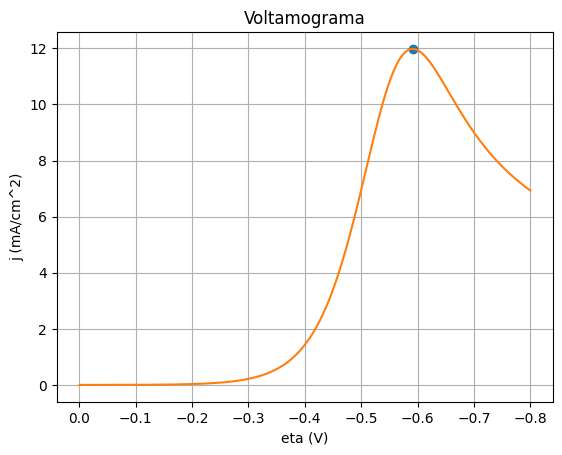

In [91]:
eta_C, j_C, C_final_C, perfiles_C = simular_C(N, 0.01)

j_max = 0
eta_pico = 0

for m in range(len(j_C)):
    if j_C[m] > j_max:
        j_max = j_C[m]
        eta_pico = eta_C[m]

print(f"Pico: {j_max/10:2f} mA/cm^2 en eta = {eta_pico:.2f} V")

plt.plot(eta_pico,j_max/10,"o")
plt.plot(eta_C, j_C / 10)
plt.xlabel("eta (V)")
plt.ylabel("j (mA/cm^2)")
plt.title("Voltamograma")
plt.grid(True)
plt.gca().invert_xaxis()
plt.show()

$$\eta=\eta_0-vt \\[2.5em]
t=\frac{\eta_0 -\eta}v \\[2.5em]$$
La vuelta $m$ guardo el perfil del instante $t=(m+1)\Delta t$ en la posición $m$ de la lista. Entonces la posición $m$ tien el perfil del tiempo
$$t=(m+1)\Delta t\quad \Longrightarrow\quad m=\frac{t}{\Delta t} -1\\[2.5em]
m=\frac{\eta_0-\eta}{v\Delta t}-1$$

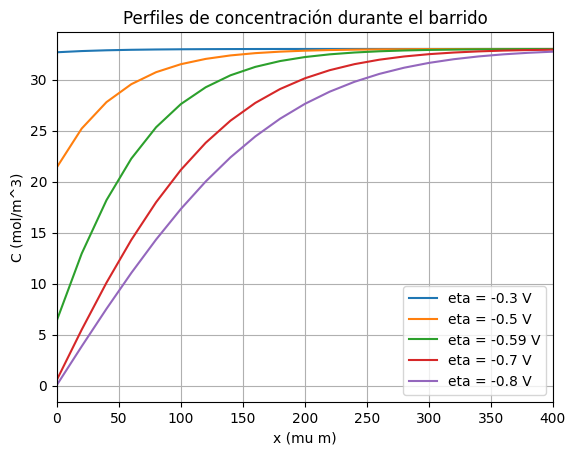

In [95]:
dt = 0.01

x = []
for i in range(N + 1):
    x.append(i * dx * 1e6)

etas_mostrar = [-0.3, -0.5, -0.59, -0.7, -0.8]

for eta_obj in etas_mostrar:
    m = int(round((eta_0 - eta_obj) / (v * dt))) - 1

    perfil_paso = perfiles_C[m]

    perfil = []
    for i in range(N):
        perfil.append(perfil_paso[i])
    perfil.append(C_bulk)

    plt.plot(x, perfil, label=f"eta = {eta_obj} V")

plt.xlim(0, 400)
plt.xlabel("x (mu m)")
plt.ylabel("C (mol/m^3)")
plt.title("Perfiles de concentración durante el barrido")
plt.grid(True)
plt.legend()
plt.show()